# Sketch plots

`sk.Plot()` and `px.Plot(sk)` draw a sketch in its own style, on a light grid. The color of every element shows its
constraint state:

- green: fully constrained;
- black: free, with degrees of freedom left;
- pink: over-constrained, where a constraint contradicts the others.

Construction elements are dashed, and projected elements are gold. Four options add what you need to see while a
sketch is drawn and constrained:

| Option | Adds |
|---|---|
| `show_constraints=True` | A sign for every constraint and the value of every dimension |
| `show_ends=True` | A blue start piece and an orange end piece on every line and arc |
| `show_direction=True` | An arrow from start to end on every line and arc |
| `show_parent=solid` | An OpenCASCADE solid projected under the sketch, its faces lightly filled and its edges black |

With `backend="plotly"`, every element shows its id when hovered. This page uses constraint sketches, which have a
section of their own. See [Constraint sketches](../constraints/index.md) for how they are drawn and dimensioned.

In [1]:
import warnings

import matplotlib.pyplot as plt
import netgen.occ as occ
import planex as px

## The state of a sketch

The example is a plate of 40 × 20 with a hole, dimensioned step by step. Without dimensions, all its elements are free
and drawn in black (a). With a corner fixed, the bottom horizontal and both sides dimensioned, the rectangle is fully
constrained and turns green, while the hole is still free (b). Once the diameter and the position of the hole are
dimensioned as well, the whole sketch is fully constrained (c).

(a) Free - under 8 degrees of freedom
(b) The rectangle constrained - under 3 degrees of freedom
(c) Fully constrained - full 0 degrees of freedom


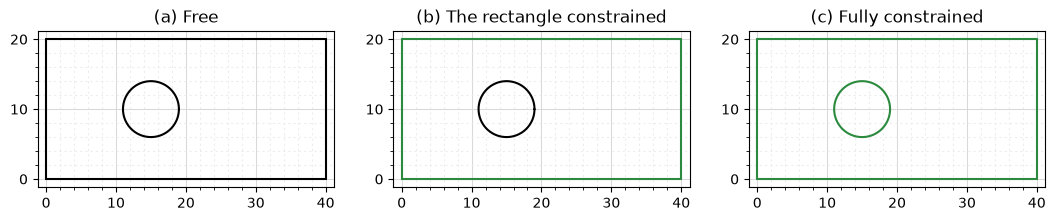

In [2]:
def plate(step=0):
    sk = px.Sketch().Rectangle(40, 20, id="plate")
    sk.Circle(15, 10, 4, id="hole")
    if step >= 1:
        sk.Constrain("plate.Point.1", px.Fix)
        sk.Constrain("plate.Line.1", px.Horizontal)
        sk.Constrain("plate.Line.1", px.Distance, 40, id="a")
        sk.Constrain("plate.Line.2", px.Distance, 20, id="b")
    if step >= 2:
        sk.Constrain("hole", px.Diameter, 8, id="d")
        sk.Constrain("hole.center", "plate.Line.4", px.Distance, 15)
        sk.Constrain("hole.center", "plate.Line.1", px.Distance, 10)
    return sk


fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
titles = ("(a) Free", "(b) The rectangle constrained", "(c) Fully constrained")
for step, (ax, title) in enumerate(zip(axes, titles)):
    sk = plate(step)
    print(title, "-", sk.status, sk.dof, "degrees of freedom")
    sk.Plot(ax=ax)
    ax.set_title(title)

## Redundant and contradicting constraints

A second length of 40, on the top side, repeats what the rectangle already fixes. It is redundant, and with
`show_constraints=True`, the redundant constraints are drawn in pink (a). A second length of 41 contradicts the first.
`Constrain` keeps it but suspends it: a `PlanexWarning` names the constraints it contradicts, the status of the sketch
is `"over"`, and the geometry stays at its last solution. The suspended constraint and the ones it contradicts are
drawn in pink (b).

redundant: ['plate.Perpendicular.2', 'plate.Perpendicular.3', 'a', 'a again']
41: over - "plate.Line.3", px.Distance, 41: no solution, it contradicts the constraints there are (plate.Perpendicular.2, plate.Perpendicular.3, a); Distance.3 is kept but not solved, the sketch is over-constrained


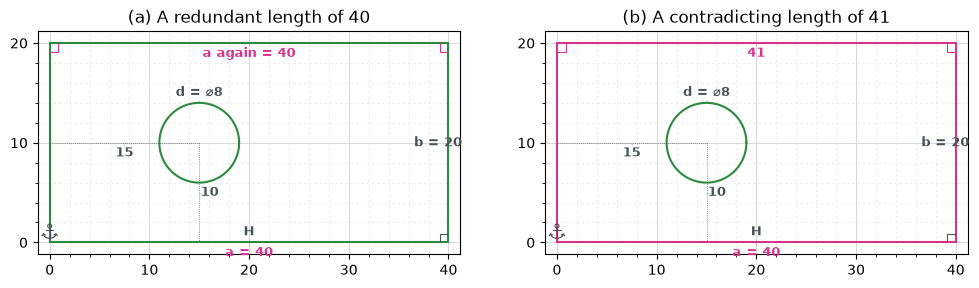

In [3]:
redundant = plate(2)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", px.PlanexWarning)
    redundant.Constrain("plate.Line.3", px.Distance, 40, id="a again")
print("redundant:", redundant.redundant)

contradicting = plate(2)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", px.PlanexWarning)
    contradicting.Constrain("plate.Line.3", px.Distance, 41)
print("41:", contradicting.status, "-", caught[0].message)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.2))
redundant.Plot(ax=left, show_constraints=True)
contradicting.Plot(ax=right, show_constraints=True)
left.set_title("(a) A redundant length of 40")
right.set_title("(b) A contradicting length of 41");

See [Fully, under- and over-constrained](../constraints/diagnosis.md) for finding and resolving such constraints.

## Constraints, ends and directions

`show_constraints` writes the value of every dimension and a sign for every other constraint: H and V for horizontal
and vertical, a square for a right angle, and an anchor for a fixed point (a). `show_ends` and `show_direction` show
how the elements were drawn. This matters for references to the start or the end of an element, such as
`"Line.3.end"`, and for options that depend on the drawing direction. The example is the fully constrained plate from
above and a slot drawn counterclockwise, with each arc continuing its line (b, c).

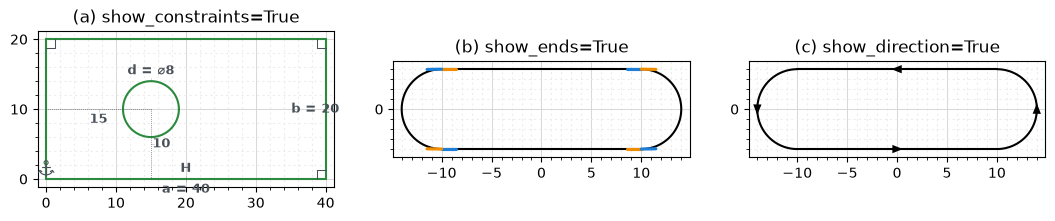

In [4]:
slot = px.QuickSketch((-10, -4)).Line(20).Arc(4, 180).Line(20).Arc(4, 180)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
plate(2).Plot(ax=axes[0], show_constraints=True)
slot.Plot(ax=axes[1], show_ends=True)
slot.Plot(ax=axes[2], show_direction=True)
for ax, title in zip(axes, ("(a) show_constraints=True", "(b) show_ends=True", "(c) show_direction=True")):
    ax.set_title(title)

## On a solid

With `show_parent`, a sketch on a face of an OpenCASCADE solid is drawn on top of that solid. The solid is projected
into the sketch's plane, with its faces lightly filled and all its edges in black, hidden ones included.

The example is a block of 80 × 50 × 20 with two bolt holes and a slot of 12 × 6 along its bottom. First the block,
its top face, and its front bottom edge, which will place the pocket:

In [5]:
block = occ.Box(occ.Pnt(0, 0, 0), occ.Pnt(80, 50, 20))
for x in (12, 68):
    block = block - occ.Cylinder(occ.Pnt(x, 25, 0), occ.Z, 4, 20)
block = block - occ.Box(occ.Pnt(0, 19, 0), occ.Pnt(80, 31, 6))
top = block.faces.Max(occ.Z)
bottom_edge = [e for e in block.edges if abs(e.center.y) < 1e-9 and abs(e.center.z) < 1e-9][0]

Then a pocket of 28 × 24 and a bore of diameter 10 are sketched on the top face. `px.Sketch(top)` puts the sketch on
the top face, with the global origin and x axis projected onto it. `Project` brings the front bottom edge into the
sketch as a construction line, drawn in gold. The pocket's first corner is dimensioned 13 from it, and its left side
26 from the origin. The sketch is fully constrained, so everything is green.

full 0 degrees of freedom, 5 edges in the face


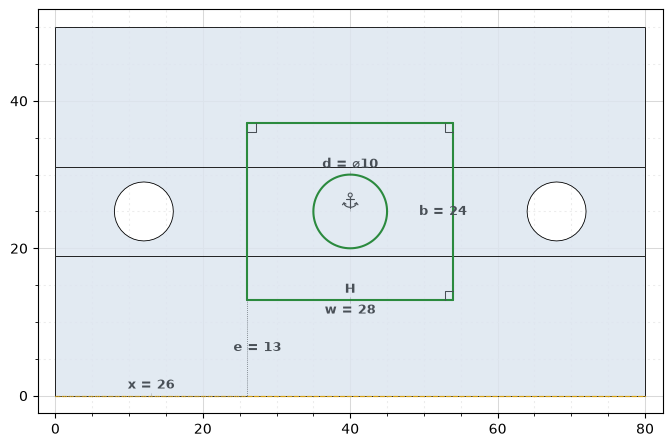

In [6]:
sk = px.Sketch(top)
sk.Project(bottom_edge, construction=True, id="bottom")
sk.Move((26, 13)).Rectangle(28, 24, id="pocket")
sk.Constrain("pocket.Line.1", px.Horizontal)
sk.Constrain("pocket.Point.1", "bottom.Edge.0", px.Distance, 13, id="e")
sk.Constrain(sk.origin, "pocket.Line.4", px.Distance, 26, id="x")
sk.Constrain("pocket.Line.1", px.Distance, 28, id="w")
sk.Constrain("pocket.Line.2", px.Distance, 24, id="b")
sk.Circle(40, 25, 5, id="bore")
sk.Constrain("bore", px.Diameter, 10, id="d")
sk.Constrain("bore.center", px.Fix)
print(sk.status, sk.dof, "degrees of freedom,", len(sk.Face().edges), "edges in the face")
sk.Plot(show_parent=block, show_constraints=True);

`px.Plot3d` shows the same in 3D, with the sketch's wires on the top face of the block:

In [7]:
px.Plot3d([block, sk])

See [Placing a sketch](../sketch/placement.md) for more on sketches on solids.

## Ids on hover

With plotly, hovering over an element or a point shows its id, and with `show_parent`, the solid's edges show their
names. This is the quickest way to find the id that a constraint or a reference needs. The example is the link from
[Tangents](../sketch/tangent.md), a quick sketch of two bosses joined by tangent lines:

In [8]:
link = px.QuickSketch()
link.Circle(0, 0, 1.5, id="boss1", construction=True)
link.Circle(6, 0, 1.0, id="boss2", construction=True)
link.Line(tangent=("boss1", "boss2"), id="upper")
link.Line(tangent=("boss1", "boss2"), reverse=True, id="lower")
link.Arc("lower", "upper", congruent="boss2", id="end2")
link.Arc("upper", "lower", congruent="boss1", id="end1")
link.Circle(0, 0, 0.6, id="hole1").Circle(6, 0, 0.4, id="hole2")
link.Plot(backend="plotly")